# Lab 11-11 · Modulation and Filtering Applications

Companion to [chapter 11-11](../../chapters/11-11-modulation-and-filtering-applications.md). Four parts: DSB-SC with carrier errors, envelope detection, images, and filter families. Run the cells in order.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

## Part 1 — DSB-SC and coherent demodulation

phase error  0 deg: demodulated amplitude 1.000
phase error 30 deg: demodulated amplitude 0.866
phase error 90 deg: demodulated amplitude 0.000


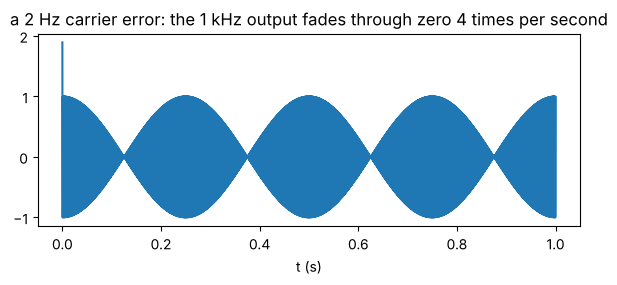

In [2]:
fs = 2e6; t = np.arange(int(fs * 0.02)) / fs; fc = 100e3
x = np.cos(2 * np.pi * 1e3 * t)
s = x * np.cos(2 * np.pi * fc * t)
b, a = signal.butter(6, 20e3, fs=fs)
for phi in (0, 30, 90):
    y = signal.filtfilt(b, a, s * np.cos(2 * np.pi * fc * t + math.radians(phi)))[5000:-5000]
    print(f"phase error {phi:2d} deg: demodulated amplitude {2 * np.sqrt(2 * np.mean(y**2)):.3f}")
tl = np.arange(int(fs * 1.0)) / fs
yl = signal.filtfilt(b, a, np.cos(2 * np.pi * 1e3 * tl) * np.cos(2 * np.pi * fc * tl) * np.cos(2 * np.pi * (fc + 2) * tl))
fig, ax = plt.subplots(figsize=(7, 2.5)); ax.plot(tl[::50], 2 * yl[::50]); ax.set_xlabel("t (s)")
ax.set_title("a 2 Hz carrier error: the 1 kHz output fades through zero 4 times per second"); plt.show()

## Part 2 — Envelope detection (guided exercise)

**Predict first:** for $m$ = 0.5 and a 5 kHz tone on a 1 MHz carrier, how does distortion change as $RC$ goes from 20 to 55 to 150 µs? An ideal diode charges the capacitor to the input whenever the input is higher; otherwise it discharges through $R$.

In [3]:
def detect(RC, m=0.5, fm=5e3, fc=1e6, cycles=6):
    fs = 100 * fc; t = np.arange(int(fs * cycles / fm)) / fs
    s = (1 + m * np.cos(2 * np.pi * fm * t)) * np.cos(2 * np.pi * fc * t)
    k = math.exp(-1 / (fs * RC)); y = np.empty_like(s); y[0] = s[0]
    for i in range(1, len(s)):
        y[i] = s[i] if s[i] > y[i - 1] * k else y[i - 1] * k
    return t, y
for RC in (20e-6, 55e-6, 150e-6):
    t, y = detect(RC)
    seg = y[t > 2 / 5e3]
    Y = np.abs(np.fft.rfft(seg - seg.mean())); f = np.fft.rfftfreq(len(seg), t[1] - t[0])
    h1 = Y[np.argmin(np.abs(f - 5e3))]; h2 = Y[np.argmin(np.abs(f - 10e3))]
    print(f"RC = {RC * 1e6:5.0f} us: second harmonic {20 * np.log10(h2 / h1):6.1f} dB below the tone")

RC =    20 us: second harmonic  -85.4 dB below the tone
RC =    55 us: second harmonic  -80.6 dB below the tone
RC =   150 us: second harmonic  -13.3 dB below the tone


Below the limit $\sqrt{1 - m^2}/(m\omega_m)$ = 55.1 µs the output tracks the envelope (residual distortion comes from carrier ripple); above it the falling half of each cycle is clipped by the exponential discharge and the second harmonic rises sharply.

## Part 3 — An image lands on the IF

In [4]:
fsm = 20e6; tm = np.arange(400000) / fsm
for frf, name in ((1000e3, "station"), (1910e3, "image")):
    y = np.cos(2 * np.pi * frf * tm) * np.cos(2 * np.pi * 1455e3 * tm)
    Y = np.abs(np.fft.rfft(y)); f = np.fft.rfftfreq(len(tm), 1 / fsm)
    print(f"{name} at {frf / 1e3:.0f} kHz -> low output at {f[np.argmax(Y * (f < 1e6))] / 1e3:.1f} kHz")

station at 1000 kHz -> low output at 455.0 kHz
image at 1910 kHz -> low output at 455.0 kHz


## Part 4 — Filter families on one specification

Butterworth 17: step overshoot  20.5 %


Chebyshev I 8 : step overshoot  23.0 %


elliptic 5    : step overshoot  15.1 %


Bessel 5      : step overshoot   0.8 %


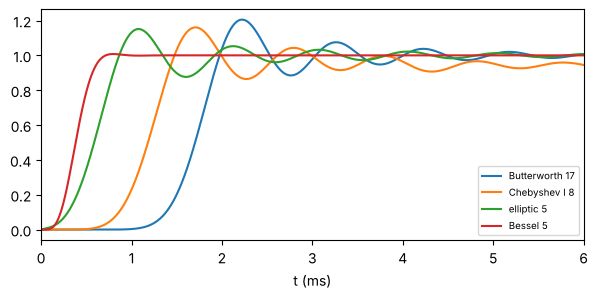

In [5]:
wp, ws = 2 * math.pi * 1e3, 2 * math.pi * 1.5e3
designs = {}
n, wn = signal.buttord(wp, ws, 0.5, 50, analog=True); designs[f"Butterworth {n}"] = signal.butter(n, wn, analog=True, output="zpk")
n, wn = signal.cheb1ord(wp, ws, 0.5, 50, analog=True); designs[f"Chebyshev I {n}"] = signal.cheby1(n, 0.5, wn, analog=True, output="zpk")
n, wn = signal.ellipord(wp, ws, 0.5, 50, analog=True); designs[f"elliptic {n}"] = signal.ellip(n, 0.5, 50, wn, analog=True, output="zpk")
designs["Bessel 5"] = signal.bessel(5, wp, analog=True, norm="mag", output="zpk")
t = np.linspace(0, 0.02, 200001)
fig, ax = plt.subplots(figsize=(7, 3))
for name, (z, pz, k) in designs.items():
    # simulate in normalized time t*wp: at the absolute scale a 17th-order model has entries near 1e65
    zn, pn, kn = z / wp, pz / wp, k * wp ** (len(z) - len(pz))
    _, y = signal.step(signal.ZerosPolesGain(zn, pn, kn), T=t * wp)
    print(f"{name:14s}: step overshoot {100 * (y.max() / y[-1] - 1):5.1f} %")
    ax.plot(t * 1e3, y, label=name)
ax.set_xlim(0, 6); ax.set_xlabel("t (ms)"); ax.legend(fontsize=7); plt.show()